In [92]:
import numpy as np
import os
import seaborn as sns
import pandas as pd
from sklearn.mixture import GaussianMixture
from matplotlib import pyplot as plt
import matplotlib.colors as mcolors

from general_solver import omt, sample_mm, mmd_rbf
from exp_functions import points_transport
from utils import generate_shape_with_exp_density, RingSampler, generate_point_cloud

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
saving_path = './figures/arc_to_Scurve/'
os.makedirs(saving_path, exist_ok=True)
# set the optimization parameters
eps = 0.01
max_iter = int(1e5)
stop_thr = 1e-6
fontsize = 22

# set the vidualization parameters
color_source = '#ff715b'
color_target = '#29335C' 
color_omt = '#eeab00'


/tmp/ipykernel_3045251/1019600990.py:26: UserWarning: You passed both c and facecolor/facecolors for the markers. c has precedence over facecolor/facecolors. This behavior may change in the future.
  ax.scatter(samples_rings_2d[:, 0], samples_rings_2d[:, 1], s=15, c=color_source, facecolors=color_source, edgecolors='none', alpha=0.7)


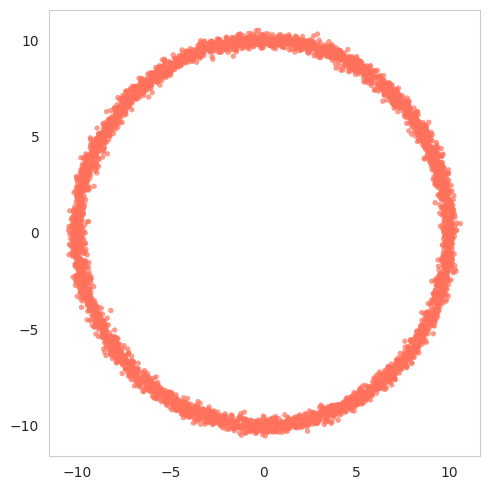

In [93]:
n_rings = 1
radii = [5] # Radii of the concentric rings
n_samples_per_ring = [5000] # Number of samples for each ring
noise_level = 0.1 # Noise level for all rings

# --- Generate data for all rings ---
all_x = []
all_y = []

for i in range(n_rings):
    x_ring, y_ring = RingSampler(radii[i], noise_level, n_samples_per_ring[i])
    all_x.append(x_ring)
    all_y.append(y_ring)

shift = [-10, 10] # Shift to center the rings around the origin
# Concatenate points from all rings
x_total = 2* np.concatenate(all_x) #+ shift[0]
y_total = 2* np.concatenate(all_y) #+ shift[1]

samples_rings_2d =np.vstack((x_total, y_total)).T

# Plot the results
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sns.set_style("whitegrid") # Set style to whitegrid for better visibility
# Plot original Swiss Roll data
ax.scatter(samples_rings_2d[:, 0], samples_rings_2d[:, 1], s=15, c=color_source, facecolors=color_source, edgecolors='none', alpha=0.7)
# ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False, which='both')
# ax.axis('equal')
# ax.text(0.02, 0.85, 'Target', fontsize=fontsize+4, transform=ax.transAxes)
ax.grid(False)
# ax.spines['top'].set_color('gray')
# ax.spines['right'].set_color('gray')
# ax.spines['left'].set_color('gray')
# ax.spines['bottom'].set_color('gray')
# ax.axis('off')
plt.tight_layout()
# ax.set_ylim([-7.5,7.5])
# ax.set_xlim([-7.5,7.5])

# plt.savefig(saving_path + 'figure_2_concentric_rings_target.pdf', dpi=300)
# plt.show()

Generating point cloud via rejection sampling...


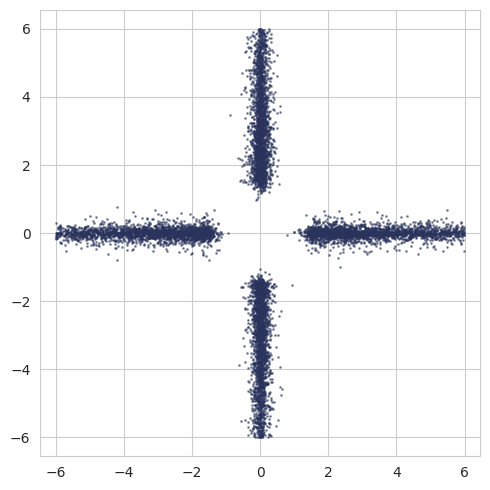

In [97]:
print("Generating point cloud via rejection sampling...")
# Fix for `np.random.random(like(X))` used inside `sun_mixture_density`
x_points, y_points = generate_point_cloud(num_points=10000)
target_smples = np.vstack((x_points, y_points)).T

plt.figure(figsize=(5, 5))
# Plot the accepted points. 
# Using a small size and low alpha mimics a glowing, misty particle effect.
plt.scatter(x_points, y_points, s=1, alpha=0.5, color=color_target)

plt.axis('equal')
# plt.axis('off')
plt.tight_layout()
plt.show()

In [98]:
K0 = 100
K1 = 4
omt_w, solver_dict = omt(
                        data_source=samples_rings_2d,
                        data_target=target_smples,
                        n_components=(K0, K1),
                        eps_gmm=eps,
                        eps_w=eps,
                        method='cvx',
                        fitting_mode_source='gauss',
                        fitting_mode_target='exp',
                        cov_type='diag',
                        max_iter=max_iter,
                        n_iter_em=2000,
                        stop_thr=stop_thr,
                        verbose=True,
                    )

Fitted a GMM with 100 components.
Model converged: True
Number of iterations: 8
--------------------------------------------------
Fitting Exp-only K=4, N=10000, D=2
  EM done: 4A  BIC=47853.3

─── Result: 0 Gaussian + 4 Exp  BIC=47853.3 ───
  Exp 1: w=0.252  b=[-1.544  0.005]  c=[8.767 9.96 ]  d=[0.593 9.296]
  Exp 2: w=0.252  b=[ 1.572 -0.002]  c=[0.602 9.586]  d=[7.804 9.741]
  Exp 3: w=0.243  b=[-0.    -1.528]  c=[ 9.949 10.462]  d=[10.414  0.595]
  Exp 4: w=0.253  b=[0.004 1.565]  c=[9.755 0.596]  d=[9.731 8.525]
Number of components in source: 100
Number of components in target: 4
Fitting mode: source=gauss, target=exp
Time taken for fitting: 0.46957969665527344 seconds
Total transportation cost: 263.0483822863664
Discrepence in marginals' weights: 4.812785878935373e-07 2.5446422126218743e-07
Number of iterations: 47700
Time taken for transportation optimzation: 5.041204452514648 seconds
Number of total iterations: 49708
Total time taken: 5.510784149169922 seconds


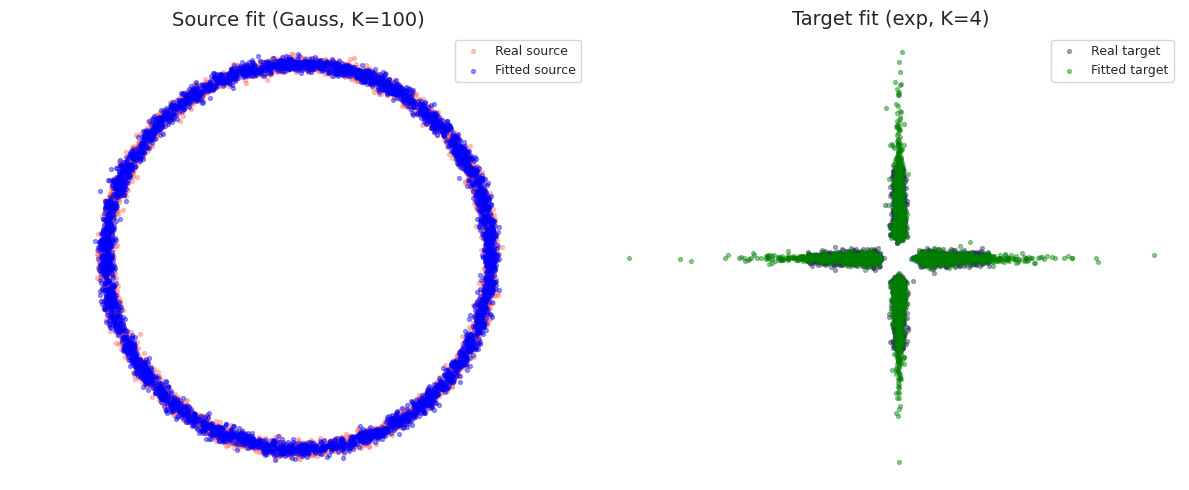

In [99]:
mm_s_gauss = solver_dict['mm_s']
mm_t_gauss = solver_dict['mm_t']

n_samples = 5000
smp_s_gauss, _ = sample_mm(mm_s_gauss, n_samples=n_samples, random_state=42)
smp_t_gauss, _ = sample_mm(mm_t_gauss, n_samples=n_samples, random_state=2)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ax = axes[0]
ax.scatter(samples_rings_2d[:, 0], samples_rings_2d[:, 1], s=8, c=color_source, alpha=0.4, label='Real source')
ax.scatter(smp_s_gauss[:, 0], smp_s_gauss[:, 1], s=8, c='blue', alpha=0.4, label='Fitted source')
ax.set_title(f'Source fit (Gauss, K={K0})', fontsize=14)
ax.legend(fontsize=9); ax.axis('equal'); ax.axis('off')

ax = axes[1]
ax.scatter(target_smples[:, 0], target_smples[:, 1], s=8, c=color_target, alpha=0.4, label='Real target')
ax.scatter(smp_t_gauss[:, 0], smp_t_gauss[:, 1], s=8, c='green', alpha=0.4, label='Fitted target')
ax.set_title(f'Target fit (exp, K={K1})', fontsize=14)
ax.legend(fontsize=9); ax.axis('equal'); ax.axis('off')

plt.tight_layout()
plt.savefig(saving_path + 'fit_quality_gauss.pdf', dpi=300)
plt.show()

In [100]:
all_x = []
all_y = []
for i in range(n_rings):
    x_ring, y_ring = RingSampler(radii[i], noise_level, 5000)
    all_x.append(x_ring)
    all_y.append(y_ring)

shift = [-10, 10] # Shift to center the rings around the origin
# Concatenate points from all rings
x_total = 2* np.concatenate(all_x) #+ shift[0]
y_total = 2* np.concatenate(all_y) #+ shift[1]

samples_rings_2d =np.vstack((x_total, y_total)).T

tnsp_smp = points_transport(samples_rings_2d, omt_w, solver_dict)

/tmp/ipykernel_3045251/1311239515.py:26: UserWarning: You passed both c and facecolor/facecolors for the markers. c has precedence over facecolor/facecolors. This behavior may change in the future.
  ax.scatter(src_x[indices], src_y[indices], s=10, c=color_source, facecolors=color_source, edgecolors='none', alpha=0.7, zorder=1, label='Source Samples')
/tmp/ipykernel_3045251/1311239515.py:27: UserWarning: You passed both c and facecolor/facecolors for the markers. c has precedence over facecolor/facecolors. This behavior may change in the future.
  ax.scatter(target_smples[:num_display, 0], target_smples[:num_display, 1], s=10, c=color_target, facecolors=color_target, edgecolors='none', alpha=0.7, zorder=1, label='Target Samples')
/tmp/ipykernel_3045251/1311239515.py:28: UserWarning: You passed both c and facecolor/facecolors for the markers. c has precedence over facecolor/facecolors. This behavior may change in the future.
  ax.scatter(tr_x, tr_y, s=10, c=color_omt, facecolors=color_o

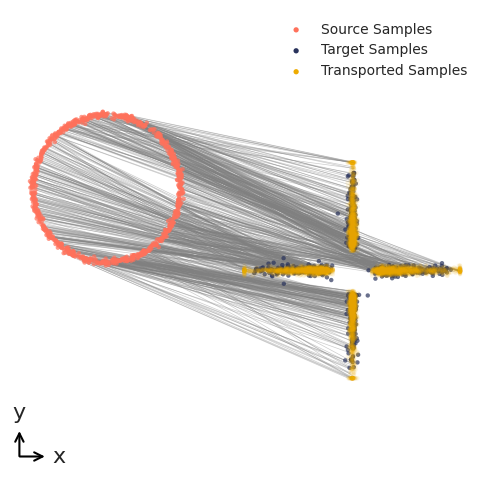

In [101]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sns.set_style("whitegrid") 
scale = .45
shift = [-15, 5]

num_total = len(samples_rings_2d)
num_display = 800  # Number of samples to visualize
indices = np.random.choice(num_total, size=min(num_total, num_display), replace=False)

# 1. Pre-calculate source coordinates for clarity
src_x = scale * samples_rings_2d[:, 0] + shift[0]
src_y = scale * samples_rings_2d[:, 1] + shift[1]
tr_x = tnsp_smp[:, 0]
tr_y = tnsp_smp[:, 1]

# 2. Draw lines between each pair of source and transported samples
# We loop through the points and plot a gray line for each correspondence
for i in range(num_display):
    ax.plot([src_x[indices[i]], tr_x[indices[i]]], [src_y[indices[i]], tr_y[indices[i]]], 
            color='gray', 
            linestyle='-', 
            linewidth=0.5, 
            alpha=0.4, 
            zorder=1) # Lower zorder to stay behind the dots

ax.scatter(src_x[indices], src_y[indices], s=10, c=color_source, facecolors=color_source, edgecolors='none', alpha=0.7, zorder=1, label='Source Samples')
ax.scatter(target_smples[:num_display, 0], target_smples[:num_display, 1], s=10, c=color_target, facecolors=color_target, edgecolors='none', alpha=0.7, zorder=1, label='Target Samples')
ax.scatter(tr_x, tr_y, s=10, c=color_omt, facecolors=color_omt, edgecolors='none', alpha=0.1, zorder=2, label='Transported Samples')

# Formatting
ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False, which='both')
ax.axis('equal')
ax.grid(False)

# Optional: Spines and Text
for spine in ax.spines.values():
    spine.set_color('gray')
    
# --- Drawing the Coordinate Triad (Bottom Left) ---
# We use axes coordinates (0 to 1) so it stays in the corner regardless of data scale
arrow_props = dict(arrowstyle='->', color='black', linewidth=1.5, mutation_scale=15)

# X-axis arrow
ax.annotate('', xy=(0.08, 0.05), xytext=(0.015, 0.05),
            xycoords='axes fraction', arrowprops=arrow_props)
ax.text(0.09, 0.05, 'x', transform=ax.transAxes, fontsize=fontsize-6, 
        verticalalignment='center')

# Y-axis arrow
ax.annotate('', xy=(0.02, 0.11), xytext=(0.02, 0.045),
            xycoords='axes fraction', arrowprops=arrow_props)
ax.text(0.02, 0.13, 'y', transform=ax.transAxes, fontsize=fontsize-6, 
        horizontalalignment='center')

legend = ax.legend(loc='upper right', scatterpoints=1, frameon=False, fontsize=10, markerscale=1.2)
for lh in legend.legend_handles: 
    lh.set_alpha(1)

ax.axis('off')
plt.tight_layout()
plt.savefig(saving_path + f'ring_to_star_gauss_exp_k0_{K0}_K1_{K1}.pdf', dpi=300)

In [83]:
K0 = 100
K1 = 30
omt_w, solver_dict = omt(
                        data_source=samples_rings_2d,
                        data_target=target_smples,
                        n_components=(K0, K1),
                        eps_gmm=eps,
                        eps_w=eps,
                        method='cvx',
                        fitting_mode_source='gauss',
                        fitting_mode_target='gauss',
                        cov_type='full',
                        max_iter=max_iter,
                        n_iter_em=2000,
                        stop_thr=stop_thr,
                        verbose=True,
                    )

Fitted a GMM with 100 components.
Model converged: True
Number of iterations: 7
--------------------------------------------------
Fitted a GMM with 30 components.
Model converged: True
Number of iterations: 32
--------------------------------------------------
Number of components in source: 100
Number of components in target: 30
Fitting mode: source=gauss, target=gauss
Time taken for fitting: 1.8085367679595947 seconds
Total transportation cost: 53.2978081580145
Discrepence in marginals' weights: 2.3639448659577768e-08 4.9108969041945905e-08
Number of iterations: 47775
Time taken for transportation optimzation: 36.83201885223389 seconds
Number of total iterations: 47814
Total time taken: 38.64055562019348 seconds


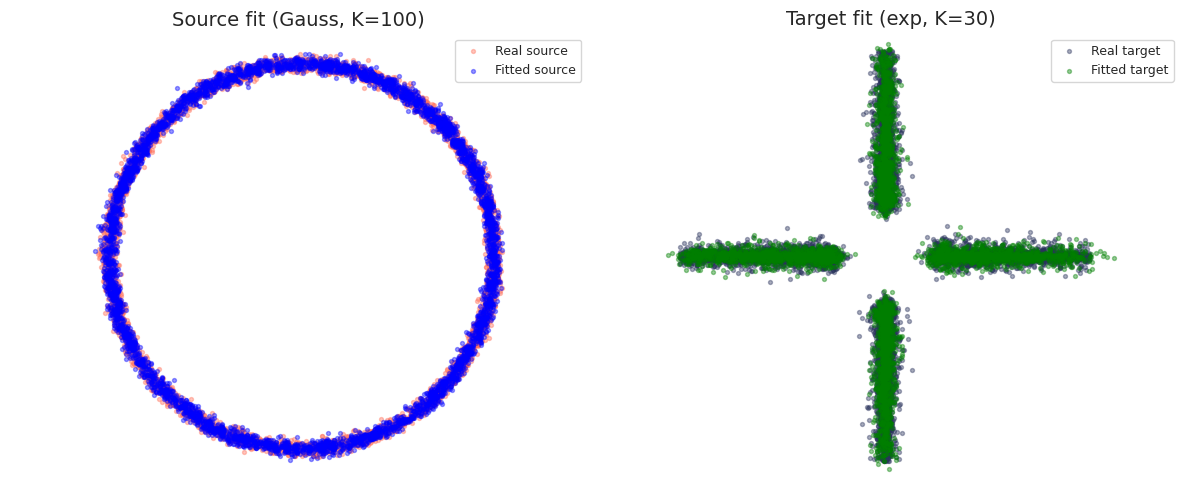

In [84]:
mm_s_gauss = solver_dict['mm_s']
mm_t_gauss = solver_dict['mm_t']

n_samples = 5000
smp_s_gauss, _ = sample_mm(mm_s_gauss, n_samples=n_samples, random_state=42)
smp_t_gauss, _ = sample_mm(mm_t_gauss, n_samples=n_samples, random_state=2)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ax = axes[0]
ax.scatter(samples_rings_2d[:, 0], samples_rings_2d[:, 1], s=8, c=color_source, alpha=0.4, label='Real source')
ax.scatter(smp_s_gauss[:, 0], smp_s_gauss[:, 1], s=8, c='blue', alpha=0.4, label='Fitted source')
ax.set_title(f'Source fit (Gauss, K={K0})', fontsize=14)
ax.legend(fontsize=9); ax.axis('equal'); ax.axis('off')

ax = axes[1]
ax.scatter(target_smples[:, 0], target_smples[:, 1], s=8, c=color_target, alpha=0.4, label='Real target')
ax.scatter(smp_t_gauss[:, 0], smp_t_gauss[:, 1], s=8, c='green', alpha=0.4, label='Fitted target')
ax.set_title(f'Target fit (exp, K={K1})', fontsize=14)
ax.legend(fontsize=9); ax.axis('equal'); ax.axis('off')

plt.tight_layout()
plt.savefig(saving_path + 'fit_quality_gauss.pdf', dpi=300)
plt.show()

In [85]:
all_x = []
all_y = []
for i in range(n_rings):
    x_ring, y_ring = RingSampler(radii[i], noise_level, 5000)
    all_x.append(x_ring)
    all_y.append(y_ring)

shift = [-10, 10] # Shift to center the rings around the origin
# Concatenate points from all rings
x_total = 2* np.concatenate(all_x) #+ shift[0]
y_total = 2* np.concatenate(all_y) #+ shift[1]

samples_rings_2d =np.vstack((x_total, y_total)).T

tnsp_smp = points_transport(samples_rings_2d, omt_w, solver_dict)

/tmp/ipykernel_3045251/2298037114.py:26: UserWarning: You passed both c and facecolor/facecolors for the markers. c has precedence over facecolor/facecolors. This behavior may change in the future.
  ax.scatter(src_x[indices], src_y[indices], s=10, c=color_source, facecolors=color_source, edgecolors='none', alpha=0.7, zorder=1, label='Source Samples')
/tmp/ipykernel_3045251/2298037114.py:27: UserWarning: You passed both c and facecolor/facecolors for the markers. c has precedence over facecolor/facecolors. This behavior may change in the future.
  ax.scatter(target_smples[:num_display, 0], target_smples[:num_display, 1], s=10, c=color_target, facecolors=color_target, edgecolors='none', alpha=0.7, zorder=1, label='Target Samples')
/tmp/ipykernel_3045251/2298037114.py:28: UserWarning: You passed both c and facecolor/facecolors for the markers. c has precedence over facecolor/facecolors. This behavior may change in the future.
  ax.scatter(tr_x, tr_y, s=10, c=color_omt, facecolors=color_o

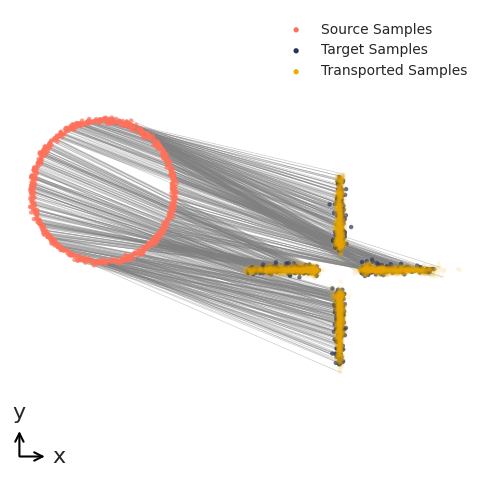

In [91]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sns.set_style("whitegrid") 
scale = .45
shift = [-15, 5]

num_total = len(samples_rings_2d)
num_display = 800  # Number of samples to visualize
indices = np.random.choice(num_total, size=min(num_total, num_display), replace=False)

# 1. Pre-calculate source coordinates for clarity
src_x = scale * samples_rings_2d[:, 0] + shift[0]
src_y = scale * samples_rings_2d[:, 1] + shift[1]
tr_x = tnsp_smp[:, 0]
tr_y = tnsp_smp[:, 1]

# 2. Draw lines between each pair of source and transported samples
# We loop through the points and plot a gray line for each correspondence
for i in range(num_display):
    ax.plot([src_x[indices[i]], tr_x[indices[i]]], [src_y[indices[i]], tr_y[indices[i]]], 
            color='gray', 
            linestyle='-', 
            linewidth=0.5, 
            alpha=0.4, 
            zorder=1) # Lower zorder to stay behind the dots

ax.scatter(src_x[indices], src_y[indices], s=10, c=color_source, facecolors=color_source, edgecolors='none', alpha=0.7, zorder=1, label='Source Samples')
ax.scatter(target_smples[:num_display, 0], target_smples[:num_display, 1], s=10, c=color_target, facecolors=color_target, edgecolors='none', alpha=0.7, zorder=1, label='Target Samples')
ax.scatter(tr_x, tr_y, s=10, c=color_omt, facecolors=color_omt, edgecolors='none', alpha=0.1, zorder=2, label='Transported Samples')

# Formatting
ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False, which='both')
ax.axis('equal')
ax.grid(False)

# Optional: Spines and Text
for spine in ax.spines.values():
    spine.set_color('gray')
    
# --- Drawing the Coordinate Triad (Bottom Left) ---
# We use axes coordinates (0 to 1) so it stays in the corner regardless of data scale
arrow_props = dict(arrowstyle='->', color='black', linewidth=1.5, mutation_scale=15)

# X-axis arrow
ax.annotate('', xy=(0.08, 0.05), xytext=(0.015, 0.05),
            xycoords='axes fraction', arrowprops=arrow_props)
ax.text(0.09, 0.05, 'x', transform=ax.transAxes, fontsize=fontsize-6, 
        verticalalignment='center')

# Y-axis arrow
ax.annotate('', xy=(0.02, 0.11), xytext=(0.02, 0.045),
            xycoords='axes fraction', arrowprops=arrow_props)
ax.text(0.02, 0.13, 'y', transform=ax.transAxes, fontsize=fontsize-6, 
        horizontalalignment='center')

legend = ax.legend(loc='upper right', scatterpoints=1, frameon=False, fontsize=10, markerscale=1.2)
for lh in legend.legend_handles: 
    lh.set_alpha(1)

ax.axis('off')
plt.tight_layout()
plt.savefig(saving_path + f'ring_to_star_gauss_gauss_k0_{K0}_K1_{K1}.pdf', dpi=300)